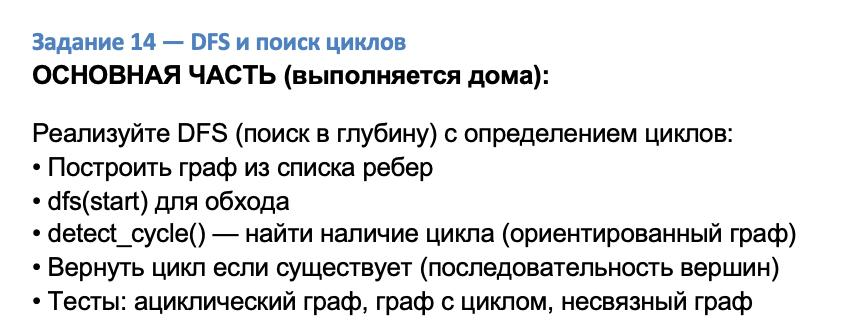

# DFS и поиск циклов в ориентированном графе

`Graph` - класс, который хранит граф, обходит его в глубину (`dfs(start)`), проверяет, есть ли в нём цикл (`detect_cycle()`), и возвращает цикл (`find_cycle()`).

### Проверка реализации
1. строим несколько графов вручную, смотрим результат; чтобы если что убрать какие-то глобальные ошибки
2. проверка через **unittest**: для каждого метода думаем, что где может сломаться, и пишем тест

## Мини теория

### граф
**Граф** - множество вершин и рёбер между ними.
в **неориентированном** графе ребро 1 - 2 работает в обе стороны, в **ориентированном** графе ребро 1 - 2 - стрелка: из 1 в 2 пройти можно, а обратно, только при наличии отдельного ребра 2 -> 1. у нас ориентированный граф

**Цикл** - путь, который заканчивается в той же вершине, с которой начался, например 2 -> 3 -> 4 -> 2. Частные случаи: **петля** 1 -> 1 (цикл из одного ребра) и пара встречных рёбер 1 -> 2, 2 -> 1 (цикл из двух рёбер; в неориентированном графе это было бы одно ребро).


### три способа хранения графа 
(V - число вершин, E - число рёбер):

| | память | есть ли ребро u -> v | перебрать соседей v |
|---|---|---|---|
| матрица смежности | O(V²) | O(1) | O(V) |
| список смежности | O(V + E) | O(степени) | O(степени) |
| список рёбер | O(E) | O(E) | O(E) |

Обход в глубину перебирает соседей, поэтому берём список смежности - словарь, где каждой вершине сопоставлен список вершин, в которые из неё ведут рёбра. пример: рёбра `[(1, 2), (1, 3), (2, 4)]` превращаются в

```
{1: [2, 3], 2: [4], 3: [], 4: []}
```

вершины 3 и 4 тоже кладем в словарь, несмотря на то что из них ничего не идет. 

### DFS, depth-first search
идея - лабиринт: идём вперёд, пока есть куда. дошли максимально - возвращаемся на шаг назад, пробуем другой поворот, и так, пока не осмотрим всё, до куда можно дойти из старта. 
посещенные вершины запоминаем (`visited`), иначе бесконечный обход в каждом цикле.

Рекурсивная запись - три шага для вершины `v`:
1. пометить `v` посещённой (`visited.add(v)`)
2. обработать `v` - записать её в порядок обхода (`order.append(v)`)
3. для каждого соседа `nxt`, в котором ещё не были, сделать то же самое

visited ставится ДО цикла по соседям, тк если ставить после, то пока идёт рекурсия, в `v` можно зайти второй раз по другому ребру.

возвращение на шаг назад происходит само: когда рекурсивный вызов для соседа закончился, возвращаемся в цикл `for` предыдущей вершины, и она берёт следующего соседа. базовый стек вызовов Python можно заменить явным стеком (`list` с `append` или `pop`) — это вторая версия обхода, `dfs_iterative`.

**Сложность** по времени O(V + E): каждая вершина попадает в `visited` один раз, и для каждой вершины её список соседей просматривается один раз - каждое ребро смотрим один раз; по памяти O(V.

### Поиск цикла в ориентированном графе

**Просто `visited` мало.** идейно хочется предположить, что если наткнулись на visited, то имеем цикл, но это не так:

ромб
```
1 -> 2 -> 4
↓       ↑
3 ──────┘
```

обход из 1: 1 -> 2 -> 4, тупик, возвращаемся в 1 и идём в 3; из 3 имеем ребро в 4, а 4 visited, но цикла при этом нет: в 4 ведут два разных пути, из 4 обратно в 3 пути нет. на паре рассматривали способ для неориентированного графа visited, not a parent; здесь он тоже неприменим тк 4 не родитель 3.

а теперь про то, **как будем искать циклы**
**три цвета.** каждая вершина находится в одном из трёх состояний:
1. white - ещё не трогали
2. gray  - лежит в текущем пути от старта обхода до вершины, где мы сейчас, т е еще не вышли из нее
3. black - вершину и всё, что из неё достижимо, обработали и из неё вышли

смотрим из вершины `v` на соседа `nxt`:
1. `nxt` white - идём в неё, как в обычном DFS
2. `nxt` gray - **нашли цикл**: серая вершина лежит в текущем пути, значит из `nxt` по этому пути можно дойти до `v`, а ребро `v -> nxt` замыкает круг
3. `nxt` black - пропускаем, цикла через это ребро нет (почему - ниже). В ромбе это ровно вершина 4, когда на неё смотрим из 3

то есть подытожив:
1. *встретили серую - цикл есть.* 
2. *ни разу не встретили серую — циклов нет.* для любого ребра `v -> nxt` вершина `nxt` чернеет раньше `v`: если `nxt` была белой, мы зашли в неё из `v` и вышли из неё раньше, чем из `v`, если `nxt` уже была чёрной - тем более раньше. если бы в графе был цикл, то, пройдя по нему, мы вернулись бы в ту же вершину с 'временем почернения' меньше её собственного - противоречие

**Как возвращать цикл.** заведём список `path` - текущий путь от старта обхода: при входе в вершину кладём её в конец (`path.append(v)`), при выходе убираем (`path.pop()`). в `path` лежат серые вершины по порядку. когда из `v` нашлось ребро в серую `nxt`, цикл - это кусок пути от `nxt` до `v` и обратно в `nxt`:

```
path = [1, 2, 3, 4, 5],  ребро 5 -> 2   =>   цикл [2, 3, 4, 5, 2]
```
1 в цикл не входит, так как через неё мы только пришли к циклу.

**Несвязный граф** - граф, где есть несоединенные вершины. обход из конкретной вершины видит только то, что из неё достижимо; чтобы не пропустить цикл в другой части графа, запускаем обход по очереди из каждой вершины, которая ещё белая.

**Сложность** O(V + E): каждая вершина один раз становится серой и один раз чёрной, каждое ребро смотрим один раз. Возвращение цикла делается один раз и стоит O(V).

## Реализация
Обозначим цвета - три состояния вершины при поиске цикла - цифрами

In [21]:
WHITE, GRAY, BLACK = 0, 1, 2     

### Реализация класса `Graph`

Данные (список смежности) и методы, которые с ними работают, соберём в один класс `Graph`.

**Построение и хранение графа:**
* `__init__(self, edges=None)` - создаёт словарь `self.adj`: вершина -> список вершин, в которые из неё ведут рёбра. если сразу передать список рёбер `edges`, конструктор сам добавит их в граф через `add_edge`. пользуемся обычным `dict`, а не `defaultdict(list)`: `dict` выдаст ошибку при обращении к несуществующему ключу, а `defaultdict` создал бы 0 - пустой список; тогда при переборе всех вершин она бы не фигурировала, а если через g[v] до нее дойти то словарь изменится во время итерации перебора и будет ошибка.
* `add_vertex(v)` - добавляет вершину в словарь с пустым списком соседей, только если её там ещё нет (чтобы повторным вызовом не затереть уже записанные рёбра).
* `add_edge(u, v)` - добавляет ребро `u -> v`: сначала кладём в граф обе вершины (включая `v`, даже если из неё ничего не выходит), потом добавляем `v` к соседям `u` в одну сторону, тк граф ориентированный.

**дополнительные методы:**
* `__len__` - `len(g)` возвращает число вершин.
* `__contains__` - `v in g` проверяет, есть ли вершина в графе.
* `__repr__` - аккуратный вывод графа через `print(g)`.

**Обход в глубину:**
* `dfs(start)` и `_dfs(v, visited, order)` - внешний метод и рекурсия(внутренний метод, снаружи не вызываем). если стартовой вершины нет в графе `ValueError`. множество `visited` и список `order` создаём заново при каждом вызове, а не храним в `self`, иначе второй запуск `dfs` увидел бы старый `visited` и ничего не обошёл.
* `dfs_iterative(start)` - то же самое без рекурсии, на явном стеке (`list` с `append` и `pop`), чтобы на глубоких графах не упираться в лимит рекурсии питона. соседей складываем через `reversed`, тк стек отдаёт последний положенный элемент: первым снимется первый сосед, порядок обхода совпадёт с рекурсивным.

**Поиск цикла:**
* `find_cycle()` и `_visit(v, color, path)` - внешний метод красит все вершины в `WHITE`, заводит текущий путь `path` и запускает `_visit` по очереди из каждой ещё белой вершины. внутри `_visit` при входе, красим вершину в `GRAY` и кладём в `path`: если попался серый сосед `nxt` - цикл найден, отрезаем хвост до `nxt` (`path[start:]`) и замыкаем цикл обратно в `nxt` (получается вид `[2, 3, 4, 5, 2]`). белого соседа обходим рекурсивно, чёрного пропускаем. если из вершины все соседи разобраны и цикла нет - красим в `BLACK` и делаем откат `path.pop()`.
* `detect_cycle()` - возвращает `True` или `False` (есть ли цикл). отдельный обход не пишем, просто проверяем `self.find_cycle() is not None` - один алгоритм, меньше шансов ошибиться.


In [22]:
class Graph:
    def __init__(self, edges=None):
        self.adj = {}                        #список смежности: вершина -> список вершин, куда из нее ведут ребра
        if edges:                            #если сразу передали список ребер - строим граф
            for u, v in edges:
                self.add_edge(u, v)

    def add_vertex(self, v):
        if v not in self.adj:                #вершина уже есть - не трогаем, иначе потеряем ее ребра
            self.adj[v] = []

    def add_edge(self, u, v):
        self.add_vertex(u)                   #обе вершины ребра обязаны попасть в граф,
        self.add_vertex(v)                   
        self.adj[u].append(v)                #ребро u -> v записываем только в одну сторону - граф ориентированный

    def __len__(self):                       #len(g) - число вершин
        return len(self.adj)

    def __contains__(self, v):               #v in g - есть ли вершина в графе
        return v in self.adj

    def __repr__(self):                      #как граф выглядит при печати
        return f'Graph({self.adj})'

    def dfs(self, start):
        if start not in self.adj:            #обходить нечего - очев ошибка
            raise ValueError(f'вершины {start} нет в графе')
        visited = set()                      #где уже были
        order = []                           #в каком порядке заходили в вершины
        self._dfs(start, visited, order)
        return order

    def _dfs(self, v, visited, order):
        visited.add(v)                       #1. отмечаем где уже были
        order.append(v)                      #2. записали в порядок обхода
        for nxt in self.adj[v]:              #3. идем по стрелкам из v
            if nxt not in visited:           #в соседе еще не были - идем в него и дальше вглубь
                self._dfs(nxt, visited, order)

    def dfs_iterative(self, start):
        if start not in self.adj:
            raise ValueError(f'вершины {start} нет в графе')
        visited = set()
        order = []
        stack = [start]                      #явный стек(last in first out, работаем только с вершиной) вместо рекурсии
        while stack:
            v = stack.pop()                  #снимаем последнюю положенную, потом обход вглубь
            if v in visited:                 #вершина могла попасть в стек дважды - пропускаем
                continue
            visited.add(v)
            order.append(v)
            for nxt in reversed(self.adj[v]):    #reversed - чтобы порядок совпал с рекурсией
                if nxt not in visited:
                    stack.append(nxt)
        return order

    def find_cycle(self):
        color = {v: WHITE for v in self.adj}     #вначале все вершины белые
        path = []                                #текущий путь от старта обхода - серые вершины по порядку
        for v in self.adj:                       #проходим по всем вершинам 
            if color[v] == WHITE:
                cycle = self._visit(v, color, path)
                if cycle is not None:
                    return cycle
        return None                              #обошли весь граф, серых не встретили - циклов нет

    def _visit(self, v, color, path):
        color[v] = GRAY                          #вошли в вершину - теперь она в текущем пути
        path.append(v)
        for nxt in self.adj[v]:
            if color[nxt] == GRAY:               #ребро ведет в серую вершину - нашли цикл
                start = path.index(nxt)          #находим, откуда в пути начинается цикл 
                return path[start:] + [nxt]      #замыкаем цикл обратно в nxt
            if color[nxt] == WHITE:              #еще не трогали - уходим вглубь
                cycle = self._visit(nxt, color, path)
                if cycle is not None:            #цикл нашелся глубже - возвращаем наверх
                    return cycle
            #черную вершину просто пропускаем - цикла через нее нет
        color[v] = BLACK                         #всех соседей разобрали - выходим из вершины
        path.pop()                               #убираем v из текущего пути
        return None

    def detect_cycle(self):
        return self.find_cycle() is not None     #цикл есть, если find_cycle вернул не None


In [23]:
#проверка построения графа
g = Graph([(1, 2), (1, 3), (2, 4)])
g.add_vertex(5)                              #изолированная вершина без ребер
print(g)
print(len(g))
print(4 in g, 9 in g)

Graph({1: [2, 3], 2: [4], 3: [], 4: [], 5: []})
5
True False


простейший граф строится правильно

In [24]:
#проверим чуть более детально на чуть более хитрых графах
TWO_PARTS = [(1, 2), (1, 3), (2, 4), (3, 4), (4, 5), (6, 7)]
TAIL_CYCLE = [(1, 2), (2, 3), (3, 4), (4, 5), (5, 2)]
SPLIT_CYCLE = [(1, 2), (1, 3), (4, 5), (5, 6), (6, 4)]

for name, edges in [('TWO_PARTS', TWO_PARTS), ('TAIL_CYCLE', TAIL_CYCLE), ('SPLIT_CYCLE', SPLIT_CYCLE)]:
    g = Graph(edges)
    print(name, g)
    print('    dfs(1):           ', g.dfs(1))
    print('    dfs_iterative(1): ', g.dfs_iterative(1))
    print('    detect_cycle():   ', g.detect_cycle())
    print('    find_cycle():     ', g.find_cycle())
    print()

TWO_PARTS Graph({1: [2, 3], 2: [4], 3: [4], 4: [5], 5: [], 6: [7], 7: []})
    dfs(1):            [1, 2, 4, 5, 3]
    dfs_iterative(1):  [1, 2, 4, 5, 3]
    detect_cycle():    False
    find_cycle():      None

TAIL_CYCLE Graph({1: [2], 2: [3], 3: [4], 4: [5], 5: [2]})
    dfs(1):            [1, 2, 3, 4, 5]
    dfs_iterative(1):  [1, 2, 3, 4, 5]
    detect_cycle():    True
    find_cycle():      [2, 3, 4, 5, 2]

SPLIT_CYCLE Graph({1: [2, 3], 2: [], 3: [], 4: [5], 5: [6], 6: [4]})
    dfs(1):            [1, 2, 3]
    dfs_iterative(1):  [1, 2, 3]
    detect_cycle():    True
    find_cycle():      [4, 5, 6, 4]



все работает как надо

### Юнит-тесты

In [25]:
import unittest

Для каждого этапа подумаем, что именно может пойти не так, и напишем на это отдельные тесты. 

**построение графа: что может сломаться?**
1. вершина, в которую рёбра только входят (сток), не попадает в словарь `adj`
2. ребро записывается в обе стороны, и граф становится неориентированным
3. изолированная вершина теряется или не учитывается в `len(g)`
4. повторный вызов `add_vertex` стирает уже добавленные рёбра вершины
5. пустой граф (`Graph()` или `Graph([])`) вызывает ошибку вместо графа длины 0

In [26]:
class TestBuild(unittest.TestCase):

    def test_sink_vertex(self):
        """вершина без исходящих ребер попадает в граф"""
        g = Graph([(1, 2)])
        self.assertIn(2, g)
        self.assertEqual(g.adj[2], [])

    def test_directed_edge(self):
        """ребро записывается только в одну сторону"""
        g = Graph([(1, 2)])
        self.assertEqual(g.adj[1], [2])
        self.assertNotIn(1, g.adj[2])

    def test_isolated_vertex(self):
        """изолированная вершина добавляется и не теряется"""
        g = Graph([(1, 2)])
        g.add_vertex(3)
        self.assertIn(3, g)
        self.assertEqual(len(g), 3)

    def test_duplicate_vertex(self):
        """повторный add_vertex не стирает старые ребра"""
        g = Graph([(1, 2)])
        g.add_vertex(1)
        self.assertEqual(g.adj[1], [2])

    def test_empty_graph(self):
        """пустой граф создается без ошибок"""
        self.assertEqual(len(Graph()), 0)
        self.assertEqual(len(Graph([])), 0)


**`dfs` и `dfs_iterative`: что может сломаться?**
1. обход идёт не вглубь, ломается порядок вершин
2. обход против стрелок
3. на графе с циклом обход зацикливается или записывает вершину дважды
4. на несвязном графе обход перескакивает в другую часть графа
5. несуществующая стартовая вершина не выдаёт `ValueError` или случайно добавляется в граф
6. итеративная версия через стек даёт разный c рекурсивной порядок обхода

In [27]:
class TestDFS(unittest.TestCase):

    def setUp(self):
        self.g = Graph(TWO_PARTS)            #новый граф перед каждым тестом

    def test_dfs_order(self):
        """порядок обхода - вглубь"""
        self.assertEqual(self.g.dfs(1), [1, 2, 4, 5, 3])

    def test_dfs_direction(self):
        """обход идет только по направлению стрелок"""
        self.assertEqual(self.g.dfs(4), [4, 5])

    def test_dfs_with_cycle(self):
        """на графе с циклом обход не зацикливается"""
        g = Graph([(1, 2), (2, 3), (3, 1)])
        self.assertEqual(g.dfs(1), [1, 2, 3])

    def test_dfs_disconnected(self):
        """несвязный граф: обход остается в своей части"""
        self.assertEqual(self.g.dfs(6), [6, 7])
        self.assertNotIn(6, self.g.dfs(1))

    def test_dfs_missing_start(self):
        """старта нет в графе - ValueError, граф не меняется"""
        with self.assertRaises(ValueError):
            self.g.dfs(99)
        self.assertNotIn(99, self.g)

    def test_dfs_iterative_matches(self):
        """итеративный обход дает тот же порядок, что и рекурсивный"""
        for v in self.g.adj:
            self.assertEqual(self.g.dfs_iterative(v), self.g.dfs(v))


#### `detect_cycle` и `find_cycle`: что может сломаться?
1. на ациклическом графе находится ложный цикл. тестируем через ромб
2. цикл или короткие частные случаи, про которые говорили раньше, не находится
3. в ответ `find_cycle` попадают вершины, через которые мы дошли до цикла, но которые в него не входят
4. в ответ попадает ветка-тупик, из которой мы уже вернулись (проверка, что работает `path.pop()`)
5. на несвязном графе проверяется только первая часть, и цикл во второй части пропускается, или на несвязном графе без циклов даётся ложный `True`
6. пустой граф или граф из одной вершины дает ошибку
7. после первого вызова где-то остаются старые цвета/путь, и повторный вызов выдаёт ложный результат

In [28]:
class TestCycles(unittest.TestCase):

    def test_acyclic_diamond(self):
        """ациклический граф (ромб) - цикла нет"""
        g = Graph([(1, 2), (1, 3), (2, 4), (3, 4), (4, 5)])
        self.assertFalse(g.detect_cycle())
        self.assertIsNone(g.find_cycle())

    def test_simple_cycle(self):
        """обычный цикл 1 -> 2 -> 3 -> 1"""
        g = Graph([(1, 2), (2, 3), (3, 1)])
        self.assertTrue(g.detect_cycle())
        self.assertEqual(g.find_cycle(), [1, 2, 3, 1])

    def test_self_loop(self):
        """петля 1 -> 1"""
        g = Graph([(1, 1)])
        self.assertTrue(g.detect_cycle())
        self.assertEqual(g.find_cycle(), [1, 1])

    def test_two_vertex_cycle(self):
        """цикл из двух встречных ребер 1 -> 2, 2 -> 1"""
        g = Graph([(1, 2), (2, 1)])
        self.assertTrue(g.detect_cycle())
        self.assertEqual(g.find_cycle(), [1, 2, 1])

    def test_cycle_with_tail(self):
        """хвост до цикла не попадает в ответ"""
        g = Graph(TAIL_CYCLE)
        self.assertTrue(g.detect_cycle())
        self.assertEqual(g.find_cycle(), [2, 3, 4, 5, 2])

    def test_dead_end_branch(self):
        """тупиковая ветка не попадает в цикл (проверка отката path.pop)"""
        g = Graph([(1, 2), (1, 3), (3, 1)])
        self.assertEqual(g.find_cycle(), [1, 3, 1])

    def test_disconnected_with_cycle(self):
        """несвязный граф: цикл только во второй части"""
        g = Graph(SPLIT_CYCLE)
        g.add_vertex(7)
        self.assertTrue(g.detect_cycle())
        self.assertEqual(g.find_cycle(), [4, 5, 6, 4])

    def test_disconnected_without_cycle(self):
        """несвязный граф без циклов"""
        g = Graph(TWO_PARTS)
        g.add_vertex(8)
        self.assertFalse(g.detect_cycle())
        self.assertIsNone(g.find_cycle())

    def test_empty_and_single(self):
        """пустой граф и граф из одной вершины"""
        g_empty = Graph()
        self.assertFalse(g_empty.detect_cycle())
        self.assertIsNone(g_empty.find_cycle())

        g_one = Graph()
        g_one.add_vertex(1)
        self.assertFalse(g_one.detect_cycle())
        self.assertIsNone(g_one.find_cycle())

    def test_repeat_call(self):
        """повторный вызов дает тот же ответ и не портит граф"""
        g = Graph(TAIL_CYCLE)
        self.assertEqual(g.find_cycle(), g.find_cycle())


In [29]:
#запуск тестов
unittest.main(argv=[''], exit=False, verbosity=2)

test_directed_edge (__main__.TestBuild.test_directed_edge)
ребро записывается только в одну сторону ... ok
test_duplicate_vertex (__main__.TestBuild.test_duplicate_vertex)
повторный add_vertex не стирает старые ребра ... ok
test_empty_graph (__main__.TestBuild.test_empty_graph)
пустой граф создается без ошибок ... ok
test_isolated_vertex (__main__.TestBuild.test_isolated_vertex)
изолированная вершина добавляется и не теряется ... ok
test_sink_vertex (__main__.TestBuild.test_sink_vertex)
вершина без исходящих ребер попадает в граф ... ok
test_acyclic_diamond (__main__.TestCycles.test_acyclic_diamond)
ациклический граф (ромб) - цикла нет ... ok
test_cycle_with_tail (__main__.TestCycles.test_cycle_with_tail)
хвост до цикла не попадает в ответ ... ok
test_dead_end_branch (__main__.TestCycles.test_dead_end_branch)
тупиковая ветка не попадает в цикл (проверка отката path.pop) ... ok
test_disconnected_with_cycle (__main__.TestCycles.test_disconnected_with_cycle)
несвязный граф: цикл только во